In [1]:
import numpy as np
import pandas as pd

# Set random seed for reproducible operational data
np.random.seed(42)

# ==========================================
# 1. SaaS & Web Stack Audit Data
# ==========================================
saas_data = {
    "tool_name": [
        "Enterprise CRM Tier",
        "Legacy Landing Page Builder",
        "Project Mgmt Tool A",
        "Project Mgmt Tool B",
        "Overpriced SEO Suite",
        "Form & Survey SaaS",
        "Email Marketing Enterprise Tier",
        "Customer Support Desk SaaS",
        "Analytics Dashboard SaaS",
        "Document E-Sign Suite",
    ],
    "department": [
        "Sales",
        "Marketing",
        "Operations",
        "Product",
        "Marketing",
        "Sales",
        "Marketing",
        "Support",
        "Executive",
        "Legal/Ops",
    ],
    "monthly_cost_usd": [
        4500,
        1200,
        800,
        950,
        1100,
        450,
        3200,
        2100,
        1500,
        600,
    ],
    "total_seats_paid": [50, 15, 40, 35, 10, 20, 25, 30, 12, 15],
    "active_seats_utilized": [18, 4, 38, 12, 3, 8, 10, 28, 4, 6],
    "is_redundant": [1, 1, 0, 1, 1, 1, 0, 0, 1, 0],
    "nexus_arch_replacement": [
        "Lightweight API CRM",
        "Native Static Web + Hosting",
        "Unified Ops Workspace",
        "Unified Ops Workspace",
        "Open-Source/Lightweight SEO",
        "Native API Form Handlers",
        "Tier-Optimized Marketing Stack",
        "Unified Support Stack",
        "Custom Python/Tableau Dashboard",
        "Native E-Sign Integration",
    ],
    "replacement_monthly_cost": [250, 20, 200, 0, 50, 10, 400, 300, 0, 50],
}
df_saas = pd.DataFrame(saas_data)
df_saas["annual_waste_usd"] = (
    df_saas["monthly_cost_usd"] - df_saas["replacement_monthly_cost"]
) * 12

# ==========================================
# 2. Quoting & Workflow Friction Data
# ==========================================
n_bids = 500
bid_ids = [f"BID-{1000 + i}" for i in range(n_bids)]
quote_response_hours = np.random.exponential(scale=24, size=n_bids).round(1)
quote_response_hours = np.clip(quote_response_hours, 1.0, 120.0)

win_prob = np.exp(-0.03 * quote_response_hours)
deal_won = np.random.binomial(1, win_prob)

deal_value_usd = np.random.normal(loc=12000, scale=3500, size=n_bids).round(-2)
deal_value_usd = np.clip(deal_value_usd, 3000, 35000)

df_workflow = pd.DataFrame(
    {
        "bid_id": bid_ids,
        "quote_response_hours": quote_response_hours,
        "deal_won": deal_won,
        "deal_value_usd": deal_value_usd,
        "workflow_type": np.where(
            quote_response_hours > 12, "Legacy Manual", "Fast-Track Auto"
        ),
    }
)

# ==========================================
# 3. Price Elasticity & Overhead Margin Data
# ==========================================
prices = np.array([2500, 2200, 1950, 1750, 1500, 1350])
demand_units = np.array([120, 165, 230, 340, 490, 680])
direct_unit_cost = 450
legacy_unit_overhead = 850
nexus_optimized_unit_overhead = 310

df_pricing = pd.DataFrame(
    {
        "price_point_usd": prices,
        "projected_unit_demand": demand_units,
        "legacy_total_cost_per_unit": direct_unit_cost + legacy_unit_overhead,
        "nexus_optimized_total_cost_per_unit": direct_unit_cost + nexus_optimized_unit_overhead,
    }
)

df_pricing["legacy_net_margin_per_unit"] = (
    df_pricing["price_point_usd"] - df_pricing["legacy_total_cost_per_unit"]
)
df_pricing["legacy_total_profit"] = (
    df_pricing["legacy_net_margin_per_unit"] * df_pricing["projected_unit_demand"]
)

df_pricing["nexus_net_margin_per_unit"] = (
    df_pricing["price_point_usd"] - df_pricing["nexus_optimized_total_cost_per_unit"]
)
df_pricing["nexus_total_profit"] = (
    df_pricing["nexus_net_margin_per_unit"] * df_pricing["projected_unit_demand"]
)

# Save to CSV files for analysis phase
df_saas.to_csv("saas_and_web_audit.csv", index=False)
df_workflow.to_csv("workflow_quoting_friction.csv", index=False)
df_pricing.to_csv("price_elasticity_margins.csv", index=False)

print(
    "✅ Nexus Ops Dataset Generated Successfully! Files saved: saas_and_web_audit.csv, workflow_quoting_friction.csv, price_elasticity_margins.csv"
)

✅ Nexus Ops Dataset Generated Successfully! Files saved: saas_and_web_audit.csv, workflow_quoting_friction.csv, price_elasticity_margins.csv


📌 PILLAR 1 & 2: FINANCIAL RE-ENGINEERING RESULTS
Current Annual SaaS/Web Spend:   $196,800.00
Nexus Ops Optimized Annual Spend: $15,360.00
Net Annual Recurring Savings:    $181,440.00
Total Cost Reduction:            92.2%
Overall Seat Utilization Rate:   52.0% (121 Ghost Seats Paid)


📌 PILLAR 3: WORKFLOW FRICTION & QUOTING ANALYSIS
Legacy Workflow Win Rate (>12h response):    36.4%
Fast-Track Auto Win Rate (<=12h response):  85.4%
Pipeline Revenue Lost to Response Delays:    $2,209,500.00


📌 PILLAR 4: PRICE ELASTICITY & MARGIN EXPANSION
Legacy Optimal Price Point:    $1,750.00 -> Generating $153,000.00 Profit
Nexus Optimized Price Point:   $1,350.00 -> Generating $401,200.00 Profit
Net Profit Expansion Potential: $248,200.00


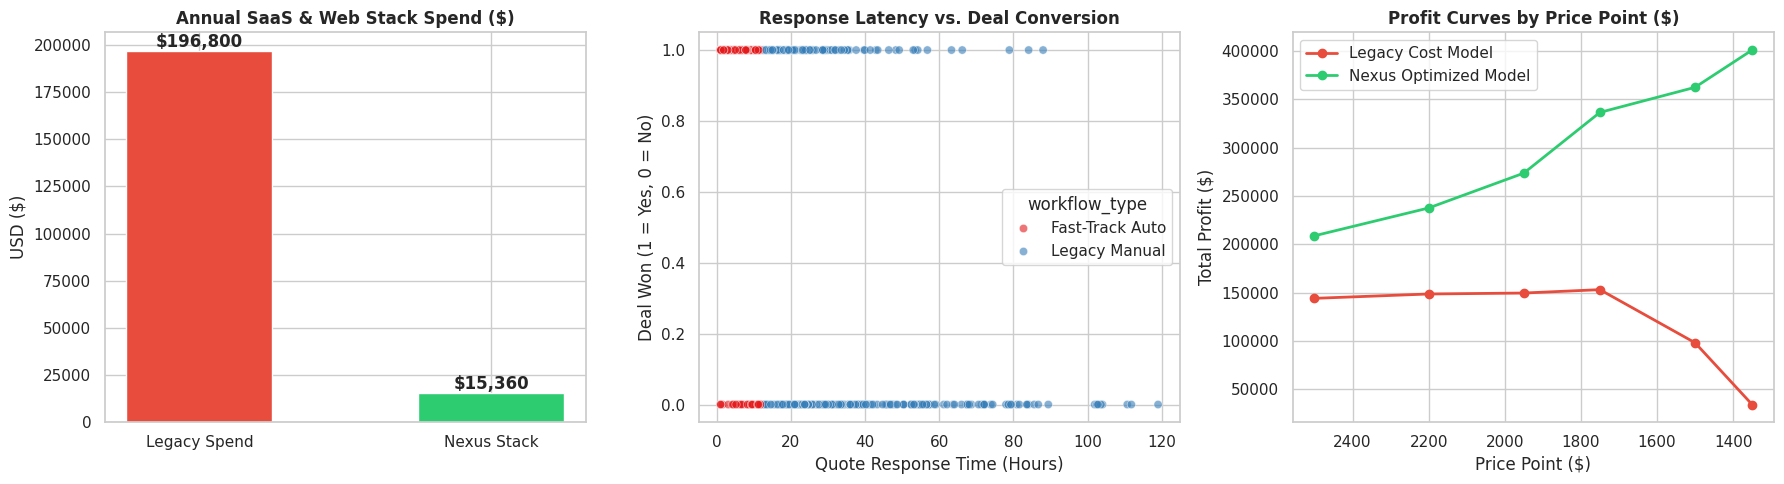

✅ Clean analysis outputs and visual summary charts generated and saved successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling for clean presentation graphics
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Load raw datasets generated in Phase 2
df_saas = pd.read_csv("saas_and_web_audit.csv")
df_workflow = pd.read_csv("workflow_quoting_friction.csv")
df_pricing = pd.read_csv("price_elasticity_margins.csv")

# ==========================================
# 1. SAAS & WEB STACK AUDIT ANALYSIS (PILLAR 1 & 2)
# ==========================================
total_current_monthly_spend = df_saas["monthly_cost_usd"].sum()
total_current_annual_spend = total_current_monthly_spend * 12

total_nexus_monthly_spend = df_saas["replacement_monthly_cost"].sum()
total_nexus_annual_spend = total_nexus_monthly_spend * 12

annual_recurring_savings = df_saas["annual_waste_usd"].sum()
overall_cost_reduction_pct = (annual_recurring_savings / total_current_annual_spend) * 100

# Calculate Ghost Seat Overhead (Paid seats logging zero active utility)
df_saas["ghost_seats"] = df_saas["total_seats_paid"] - df_saas["active_seats_utilized"]
df_saas["seat_utilization_rate"] = (df_saas["active_seats_utilized"] / df_saas["total_seats_paid"]) * 100
total_paid_seats = df_saas["total_seats_paid"].sum()
total_active_seats = df_saas["active_seats_utilized"].sum()
overall_seat_utilization = (total_active_seats / total_paid_seats) * 100

print("==================================================")
print("📌 PILLAR 1 & 2: FINANCIAL RE-ENGINEERING RESULTS")
print("==================================================")
print(f"Current Annual SaaS/Web Spend:   ${total_current_annual_spend:,.2f}")
print(f"Nexus Ops Optimized Annual Spend: ${total_nexus_annual_spend:,.2f}")
print(f"Net Annual Recurring Savings:    ${annual_recurring_savings:,.2f}")
print(f"Total Cost Reduction:            {overall_cost_reduction_pct:.1f}%")
print(f"Overall Seat Utilization Rate:   {overall_seat_utilization:.1f}% ({total_paid_seats - total_active_seats} Ghost Seats Paid)")
print("\n")

# ==========================================
# 2. WORKFLOW & QUOTING FRICTION ANALYSIS (PILLAR 3)
# ==========================================
legacy_deals = df_workflow[df_workflow["workflow_type"] == "Legacy Manual"]
auto_deals = df_workflow[df_workflow["workflow_type"] == "Fast-Track Auto"]

legacy_win_rate = (legacy_deals["deal_won"].sum() / len(legacy_deals)) * 100
auto_win_rate = (auto_deals["deal_won"].sum() / len(auto_deals)) * 100

total_revenue_lost_to_delay = legacy_deals[legacy_deals["deal_won"] == 0]["deal_value_usd"].sum()

print("==================================================")
print("📌 PILLAR 3: WORKFLOW FRICTION & QUOTING ANALYSIS")
print("==================================================")
print(f"Legacy Workflow Win Rate (>12h response):    {legacy_win_rate:.1f}%")
print(f"Fast-Track Auto Win Rate (<=12h response):  {auto_win_rate:.1f}%")
print(f"Pipeline Revenue Lost to Response Delays:    ${total_revenue_lost_to_delay:,.2f}")
print("\n")

# ==========================================
# 3. PRICE ELASTICITY & MARGIN MODELING (PILLAR 4)
# ==========================================
# Finding optimal profit point under legacy vs Nexus cost structure
legacy_max_profit = df_pricing.loc[df_pricing["legacy_total_profit"].idxmax()]
nexus_max_profit = df_pricing.loc[df_pricing["nexus_total_profit"].idxmax()]

print("==================================================")
print("📌 PILLAR 4: PRICE ELASTICITY & MARGIN EXPANSION")
print("==================================================")
print(f"Legacy Optimal Price Point:    ${legacy_max_profit['price_point_usd']:,.2f} -> Generating ${legacy_max_profit['legacy_total_profit']:,.2f} Profit")
print(f"Nexus Optimized Price Point:   ${nexus_max_profit['price_point_usd']:,.2f} -> Generating ${nexus_max_profit['nexus_total_profit']:,.2f} Profit")
print(f"Net Profit Expansion Potential: ${nexus_max_profit['nexus_total_profit'] - legacy_max_profit['legacy_total_profit']:,.2f}")
print("==================================================")

# ==========================================
# 4. GENERATE EXECUTIVE VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: SaaS Spend Comparison
categories = ['Legacy Spend', 'Nexus Stack']
costs = [total_current_annual_spend, total_nexus_annual_spend]
axes[0].bar(categories, costs, color=['#e74c3c', '#2ecc71'], width=0.5)
axes[0].set_title('Annual SaaS & Web Stack Spend ($)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('USD ($)')
for i, v in enumerate(costs):
    axes[0].text(i, v + 2000, f"${v:,.0f}", ha='center', fontweight='bold')

# Chart 2: Quote Response Time vs Win Rate
sns.scatterplot(data=df_workflow, x='quote_response_hours', y='deal_won', hue='workflow_type', ax=axes[1], alpha=0.6, palette='Set1')
axes[1].set_title('Response Latency vs. Deal Conversion', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Quote Response Time (Hours)')
axes[1].set_ylabel('Deal Won (1 = Yes, 0 = No)')

# Chart 3: Profit Curves (Legacy Overhead vs. Nexus Optimized)
axes[2].plot(df_pricing['price_point_usd'], df_pricing['legacy_total_profit'], marker='o', label='Legacy Cost Model', color='#e74c3c', linewidth=2)
axes[2].plot(df_pricing['price_point_usd'], df_pricing['nexus_total_profit'], marker='o', label='Nexus Optimized Model', color='#2ecc71', linewidth=2)
axes[2].set_title('Profit Curves by Price Point ($)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Price Point ($)')
axes[2].set_ylabel('Total Profit ($)')
axes[2].legend()
axes[2].invert_xaxis() # Higher price to lower price

plt.tight_layout()
plt.savefig("nexus_ops_executive_summary_charts.png", dpi=300)
plt.show()

# Export clean summary file for Tableau / Portfolio
df_saas.to_csv("processed_saas_summary.csv", index=False)
df_pricing.to_csv("processed_pricing_elasticity.csv", index=False)
print("✅ Clean analysis outputs and visual summary charts generated and saved successfully!")